#   **INTRODUCTION** 
In this work We tried to implement Knowledge Distillation(KD) technique as proposed by Geofrey Hinton in thier paper titled  "Distilling the Knowledge in a Neural Network" the technique was adopted in our paper called Lighweight Plant Disease Detection Model for Embedded Device with the aim of achieving a lighter CNN model for plant disease detection.
* **Goal**: 
Our aim is to developed a deep learning model that will aid African farmers in detecting diseases that are affecting thier crops using thier smartphones.the start of the art CNN models are not suitable for deployment on smartphones due to thier sizes and huge number of parametres. We therefore, compressed the model using KD to reduce model parameters while keeping the performance. we use open source plant disease detection dataset organized by PlantVIllage to train and validate our model.
* **Contribution:** 
To obtain a lighweight model that will be suitable for deployment on embedded devices such as smartphone 

# 1- Uplaoding necessary libraries 

In [1]:
import os
import pickle
import zipfile
import random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from shutil import copyfile
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    BatchNormalization, Conv2D, MaxPooling2D, Activation, Flatten, Dropout, Dense
)
from tensorflow.keras import backend as K
from sklearn.preprocessing import LabelBinarizer
from keras.preprocessing import image
import matplotlib.pyplot as plt

#  2- How Does Knowledge Distillation Works?


Knowledge distillation is a technique of model compression that employs teacher-student learning. In this technique, a large, cumbersome pre-trained model called the teacher model is trained first on a large dataset. The knowledge learned by the teacher model is transferred (distilled) to a shallow lightweight model called the student model, whereby the student mimics the performance of the teacher model despite its shallow nature. The student model size is relatively reduced without sacrificing accuracy. Figure.1 presents the architecture of the knowledge distillation technique.  
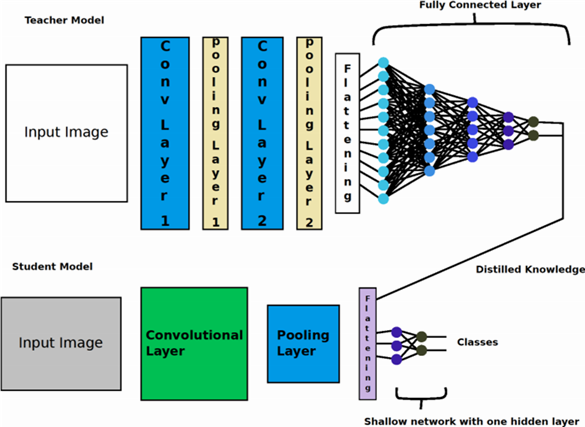

# 3- Creating Distiller Class 

## Construct `Distiller()` class


In [2]:
import splitfolders
splitfolders.ratio('plantvillage-dataset/color', output="output", seed=1337, ratio=(.8, 0.1,0.1))

# 4- Flowing Images from directory

In [3]:
TRAINING_DIR = "./output/train"
train_datagen = ImageDataGenerator(rescale=1.0/255 )
train_generator = train_datagen.flow_from_directory(TRAINING_DIR,
                                                    class_mode='categorical',
                                                    batch_size=500,
                                                    target_size=(250, 250))


VALIDATION_DIR = "./output/test"
validation_datagen = ImageDataGenerator(rescale=1.0/255.)
validation_generator = validation_datagen.flow_from_directory(VALIDATION_DIR,
                                                              class_mode='categorical',
                                                              batch_size=500,
                                                              target_size=(250, 250))

Found 43429 images belonging to 38 classes.
Found 5459 images belonging to 38 classes.


## Sample Images From the Dataset


In [ ]:
def plotImages(images_arr):
    fig, axes = plt.subplots(1, 5, figsize=(20,20))
    axes = axes.flatten()
    for img, ax in zip( images_arr, axes):
        ax.imshow(img)
    plt.tight_layout()
    plt.show()
    
    
augmented_images = [train_generator[0][0][0] for i in range(5)]
plotImages(augmented_images)

# 5- Getting Categorical Labels


In [ ]:
train_y = train_generator.classes

# 6- Converting categorical labels to binary otherwise called (Encoding)


In [ ]:
label_binarizer = LabelBinarizer()
image_labels = label_binarizer.fit_transform(train_y)
pickle.dump(label_binarizer,open('label_transform.pkl', 'wb'))
n_classes = len(label_binarizer.classes_)

# 7- Create student and teacher models

In [ ]:
# Create the teacher
teacher = keras.Sequential(name="teacher")
inputShape = (250, 250, 3)
chanDim = -1
if K.image_data_format() == "channels_first":
    inputShape = (3, 250, 250)
    chanDim = 1
    
# Residual block function
def residual_block(x, filters, strides=(1, 1), downsample=False):
    identity = x
    if downsample:
        identity = Conv2D(filters, (1, 1), strides=strides)(identity)
    x = Conv2D(filters, (3, 3), strides=strides, padding="same")(x)
    x = BatchNormalization(axis=chanDim)(x)
    x = Activation("relu")(x)
    x = Conv2D(filters, (3, 3), padding="same")(x)
    x = BatchNormalization(axis=chanDim)(x)
    x = Add()([x, identity])
    x = Activation("relu")(x)
    return x

teacher.add(Conv2D(32, (3, 3), padding="same",input_shape=inputShape))
teacher.add(Activation("relu"))
teacher.add(BatchNormalization(axis=chanDim))
teacher.add(MaxPooling2D(pool_size=(3, 3)))
teacher.add(Dropout(0.25))

teacher.add(residual_block(teacher.layers[-1].output, 64))
teacher.add(MaxPooling2D(pool_size=(2, 2)))
teacher.add(Dropout(0.25))

teacher.add(residual_block(teacher.layers[-1].output, 128))
teacher.add(MaxPooling2D(pool_size=(2, 2)))
teacher.add(Dropout(0.25))

teacher.add(Flatten())
teacher.add(Dense(1024))
teacher.add(Activation("relu"))
teacher.add(BatchNormalization())
teacher.add(Dropout(0.5))
teacher.add(Dense(n_classes))


# Create the student
student = keras.Sequential(
    [
        keras.Input(shape=(250, 250, 3)),
        layers.Conv2D(16, (3, 3), strides=(2, 2), padding="same"),
        layers.LeakyReLU(alpha=0.2),
        layers.MaxPooling2D(pool_size=(2, 2), strides=(1, 1), padding="same"),
        layers.Conv2D(32, (3, 3), strides=(2, 2), padding="same"),
        layers.LeakyReLU(alpha=0.2),
        layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding="same"),
        layers.Flatten(),
        layers.Dense(n_classes),
    ],
    name="student",
)

# Clone student for later comparison
student_scratch = keras.models.clone_model(student)


# 8- Displaying the model summary


In [ ]:
teacher.summary()

In [ ]:
student.summary()

# 9- Compiling Teacher Model for training


In [ ]:
# Train teacher as usual
teacher.compile(
    optimizer=keras.optimizers.legacy.Adam(),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['acc'],
)


# 10- Train the teacher


In [ ]:
teacher_history=teacher.fit(train_generator, validation_data=validation_generator, epochs=5)


# 11- Plotting Teacher Model Accuracy and loss Curves


In [ ]:
import matplotlib.pyplot as plt
acc = teacher_history.history['acc']
val_acc = teacher_history.history['val_acc']
loss = teacher_history.history['loss']
val_loss = teacher_history.history['val_loss']
print(range(1, len(acc) + 1))

epochs = range(1, len(acc) + 1)
#Train and validation accuracy
plt.plot(epochs, acc, 'b', label='Training accurarcy')
plt.plot(epochs, val_acc, 'r', label='Validation accurarcy')
plt.title('Training and Validation accurarcy')
plt.legend()



plt.figure()
#Train and validation loss
plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and Validation loss')
plt.legend()
plt.show()

# 12-Distilling teacher knowledge to student Model


In [ ]:
# Initialize and compile distiller
distiller = Distiller(student=student, teacher=teacher)
distiller.compile(optimizer=keras.optimizers.legacy.Adam(), metrics=['acc'],
    student_loss_fn=keras.losses.CategoricalCrossentropy(from_logits=True),
    distillation_loss_fn=keras.losses.KLDivergence(),alpha=0.1,temperature=10,)

# Distill teacher to student
student_history=distiller.fit(train_generator, validation_data=validation_generator, epochs=5)


## Plotting Student model Accuracy and loss curves


In [ ]:
import matplotlib.pyplot as plt
acc = student_history.history['acc']
val_acc =student_history.history['val_acc']
loss = student_history.history['distillation_loss']
val_loss = student_history.history['student_loss']
print(range(1, len(acc) + 1))

epochs = range(1, len(acc) + 1)
#Train and validation accuracy
plt.plot(epochs, acc, 'b', label='Training accurarcy')
plt.plot(epochs, val_acc, 'r', label='Validation accurarcy')
plt.title('Training and Validation accurarcy')
plt.legend()



plt.figure()
#Train and validation loss
plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and Validation loss')
plt.legend()
plt.show()

## Train student from scratch for comparison


In [ ]:
# Train student as doen usually
student_scratch.compile(
    optimizer=keras.optimizers.legacy.Adam(),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['acc'],
)

# Train and evaluate student trained from scratch.
student_scratch.fit(train_generator, epochs=1)
std_history=student_scratch.evaluate(validation_generator)

# 13 Conclusion
In conclusion, it can be seen that that teacher model was having over 52M parametres, while the student model was just having a little above 1M  parameters. this makes our proposed student model suitable for deployment on embeded device.  the inresting thing about this work is that the performance of the student is somewhat similar to that  of teacher model.
*  If the teacher is trained for 10 full epochs and the student is distilled on this teacher
for 5 full epochs, you should in this example experience a performance boost compared to
training the same student model from scratch, and even compared to the teacher itself.
You should expect the teacher to have accuracy around 97.6%, the student trained from
scratch should be around 96%, and the distilled student should be around 98.1%. Remove
or try out different seeds to use different weight initializations, This performances may change depending on the stochastic nature of the environmental setup.